Imports and environment

In [1]:
# %pip install -q pandas numpy matplotlib scipy
from pathlib import Path
from itertools import combinations
from collections import Counter
from datetime import datetime, timezone
import hashlib
import io
import json
import os
import re
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from IPython.display import display, Markdown

pd.set_option("display.max_colwidth", 105)
SEED = 42
SYSTEM_ORDER = ["A", "B", "C", "D", "E"]
SYSTEM_LABELS = {
    "A": "A — No retrieval",
    "B": "B — BM25",
    "C": "C — Dense FAISS",
    "D": "D — Hybrid + reranker",
    "E": "E — Hybrid RRF",
}
QUESTION_ORDER = [
    "direct_factual",
    "conceptual_explanatory",
    "multi_paper_comparison",
    "unanswerable_insufficient_evidence",
]
SUCCESS_STATUSES = {"answered", "insufficient_evidence"}
print("Notebook 11 analysis environment ready. No LLM requests will be made.")

Notebook 11 analysis environment ready. No LLM requests will be made.


Set input and output paths

In [2]:
RUN_ID = "0e2edaa48dd2"
JUDGE_RUN_ID = "e801a72b75bb"
DRIVE_PROJECT = Path("/content/drive/MyDrive/NLP Project")
RUN_DIR = DRIVE_PROJECT / "data/answer_generation/experimental_study" / RUN_ID

# On Colab keep SOURCE_MODE="drive". To analyze a downloaded ZIP, choose "zip".
SOURCE_MODE = os.environ.get("NB11_SOURCE_MODE", "drive").strip().lower()
ZIP_PATH = Path(os.environ.get("NB11_ZIP_PATH", "/content/notebook10_results.zip"))
DEFAULT_OUTPUT = (RUN_DIR / "notebook11_analysis") if SOURCE_MODE == "drive" else Path("/content/notebook11_analysis")
OUTPUT_DIR = Path(os.environ.get("NB11_OUTPUT_DIR", str(DEFAULT_OUTPUT)))
FIG_DIR = OUTPUT_DIR / "figures"

if SOURCE_MODE == "drive" and not RUN_DIR.is_dir():
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except ImportError:
        pass

if SOURCE_MODE not in {"drive", "zip"}:
    raise ValueError("SOURCE_MODE must be 'drive' or 'zip'.")
if SOURCE_MODE == "drive" and not RUN_DIR.is_dir():
    raise FileNotFoundError(
        f"Notebook 10 run directory not found: {RUN_DIR}. "
        "Mount Google Drive or set SOURCE_MODE='zip'."
    )
if SOURCE_MODE == "zip" and not ZIP_PATH.is_file():
    raise FileNotFoundError(f"ZIP not found: {ZIP_PATH}")

# Create report directories only after verifying/mounting the data source.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)


def read_run_csv(relative_name, **kwargs):
    if SOURCE_MODE == "drive":
        path = RUN_DIR / relative_name
        if not path.is_file():
            raise FileNotFoundError(path)
        return pd.read_csv(path, **kwargs)
    with zipfile.ZipFile(ZIP_PATH) as archive:
        member = f"{RUN_ID}/{relative_name}"
        if member not in archive.namelist():
            raise FileNotFoundError(f"Archive member missing: {member}")
        return pd.read_csv(io.BytesIO(archive.read(member)), **kwargs)


def read_run_json(relative_name):
    if SOURCE_MODE == "drive":
        path = RUN_DIR / relative_name
        if not path.is_file():
            raise FileNotFoundError(path)
        return json.loads(path.read_text(encoding="utf-8"))
    with zipfile.ZipFile(ZIP_PATH) as archive:
        member = f"{RUN_ID}/{relative_name}"
        return json.loads(archive.read(member).decode("utf-8"))


print("Input mode:", SOURCE_MODE)
print("Notebook 10 run:", RUN_ID)
print("Judge run:", JUDGE_RUN_ID)
print("Analysis output folder:", OUTPUT_DIR)

Input mode: drive
Notebook 10 run: 0e2edaa48dd2
Judge run: e801a72b75bb
Analysis output folder: /content/drive/MyDrive/NLP Project/data/answer_generation/experimental_study/0e2edaa48dd2/notebook11_analysis


Load authoritative master CSV files

In [3]:
run_config = read_run_json("run_config.json")
judge_config = read_run_json(f"judge_config_{JUDGE_RUN_ID}.json")
questions = read_run_csv(
    "study_all_95_questions/all_95_questions.csv",
    dtype={"question_id": "string"},
)
generations = read_run_csv(
    "answers_all_systems.csv", dtype={"question_id": "string", "system": "string"}
)
evaluations = read_run_csv(
    f"answer_evaluation_{JUDGE_RUN_ID}.csv",
    dtype={"question_id": "string", "system": "string"},
)

print("Questions:", len(questions))
print("Generations:", len(generations))
print("Evaluations:", len(evaluations))
print("Generator:", run_config.get("ollama_model", "not recorded"))
print("Judge:", judge_config.get("judge_model", "not recorded"))
display(questions.groupby(["question_type", "answerable"], dropna=False).size().rename("n").reset_index())

Questions: 95
Generations: 475
Evaluations: 475
Generator: qwen3:8b
Judge: qwen3:8b


,question_type,answerable,n
0,conceptual_explanatory,True,24
1,direct_factual,True,22
2,multi_paper_comparison,True,24
3,unanswerable_insufficient_evidence,False,25


Strict integrity checks and answer–judge matching

In [4]:
def parse_bool(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    s = str(value).strip().lower()
    if s in {"true", "1", "yes"}:
        return True
    if s in {"false", "0", "no"}:
        return False
    raise ValueError(f"Unrecognized answerable flag: {value!r}")


def answer_fingerprint(row):
    """Must match Notebook 10 exactly; do not change the key set or encoding."""
    keys = [
        "question_id", "system", "status", "answer", "citations_json",
        "cited_sources_json", "all_context_sources_json",
    ]
    payload = {}
    for key in keys:
        value = row.get(key, "")
        if value is None or (isinstance(value, float) and pd.isna(value)) or value is pd.NA:
            payload[key] = ""
        else:
            payload[key] = str(value)
    return hashlib.sha256(
        json.dumps(payload, sort_keys=True, ensure_ascii=False).encode()
    ).hexdigest()


mandatory_generation = {
    "question_id", "system", "answerable", "question_type", "question", "reference_answer",
    "status", "answer", "citations_json", "cited_sources_json", "all_context_sources_json",
    "run_id", "generation_latency_ms",
}
mandatory_evaluation = {
    "question_id", "system", "generation_answer_hash", "evaluation_status",
    "judge_run_id", "answer_correctness_0_4", "answer_relevance_0_4",
    "faithfulness_0_4", "citation_support_0_4", "abstention_correct_on_corpus_label",
}
for name, frame, required in [
    ("generations", generations, mandatory_generation),
    ("evaluations", evaluations, mandatory_evaluation),
]:
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"{name} missing required columns: {sorted(missing)}")
    if frame.duplicated(["question_id", "system"]).any():
        raise ValueError(f"{name}: duplicate question/system pairs detected")

if questions["question_id"].duplicated().any():
    raise ValueError("Duplicate question IDs in gold-question CSV")

question_ids = set(questions["question_id"].astype(str))
expected_pairs = {(qid, sys) for qid in question_ids for sys in SYSTEM_ORDER}
observed_g = set(zip(generations.question_id.astype(str), generations.system.astype(str)))
observed_e = set(zip(evaluations.question_id.astype(str), evaluations.system.astype(str)))
if observed_g != expected_pairs:
    raise ValueError(
        f"Generation coverage mismatch: {len(expected_pairs - observed_g)} missing, "
        f"{len(observed_g - expected_pairs)} extra pairs"
    )
if observed_e != expected_pairs:
    raise ValueError(
        f"Evaluation coverage mismatch: {len(expected_pairs - observed_e)} missing, "
        f"{len(observed_e - expected_pairs)} extra pairs"
    )
if len(question_ids) != 95:
    raise ValueError(f"Expected 95 questions; found {len(question_ids)}")
if not generations["status"].isin(SUCCESS_STATUSES).all():
    raise ValueError("Some generation tasks are not successful")
if not evaluations["evaluation_status"].eq("evaluated").all():
    raise ValueError("Some judge tasks are not evaluated")
if not generations["run_id"].astype(str).eq(RUN_ID).all():
    raise ValueError("Generation run ID differs from requested run")
if not evaluations["judge_run_id"].astype(str).eq(JUDGE_RUN_ID).all():
    raise ValueError("Judge run ID differs from requested judge run")

# Validate source-question labels and IDs against the saved question file.
gold = questions[["question_id", "question_type", "answerable"]].copy()
gold = gold.rename(columns={"question_type": "gold_question_type", "answerable": "gold_answerable"})
label_check = generations.merge(gold, on="question_id", how="left", validate="many_to_one")
if not label_check.apply(lambda r: parse_bool(r.answerable) == parse_bool(r.gold_answerable), axis=1).all():
    raise ValueError("Generation answerability labels disagree with question dataset")
if not label_check["question_type"].eq(label_check["gold_question_type"]).all():
    raise ValueError("Generation question categories disagree with question dataset")

generations = generations.copy()
generations["current_generation_hash"] = generations.apply(answer_fingerprint, axis=1)
results = generations.merge(
    evaluations,
    on=["question_id", "system"],
    how="inner",
    validate="one_to_one",
    suffixes=("_generation", "_judge"),
)
if not results["current_generation_hash"].eq(results["generation_answer_hash"]).all():
    mismatch = results.loc[
        ~results.current_generation_hash.eq(results.generation_answer_hash),
        ["question_id", "system"],
    ]
    raise ValueError(f"Judge scores refer to outdated answers:\n{mismatch.head(10)}")

results["answerable_bool"] = results["answerable"].map(parse_bool)
results["abstained"] = results["status"].eq("insufficient_evidence")
results["answered"] = results["status"].eq("answered")
results["rag_answered"] = results["system"].ne("A") & results["answered"]
results["abstention_aligned"] = (results["abstained"] == ~results["answerable_bool"])

score_fields = [
    "answer_correctness_0_4", "answer_relevance_0_4", "faithfulness_0_4", "citation_support_0_4"
]
for field in score_fields:
    results[field] = pd.to_numeric(results[field], errors="coerce")
    if results[field].dropna().between(0, 4).eq(False).any():
        raise ValueError(f"{field} contains out-of-range scores")

if results.loc[results.answerable_bool, "answer_correctness_0_4"].isna().any():
    raise ValueError("Missing correctness scores on answerable questions")
if results.loc[~results.answerable_bool, "answer_correctness_0_4"].notna().any():
    raise ValueError("Correctness scores should be N/A for provisionally unanswerable questions")
if results["answer_relevance_0_4"].isna().any():
    raise ValueError("Missing answer relevance scores")
if results.loc[results.rag_answered, ["faithfulness_0_4", "citation_support_0_4"]].isna().any().any():
    raise ValueError("Missing grounding scores for answered RAG outputs")
if results.loc[~results.rag_answered, ["faithfulness_0_4", "citation_support_0_4"]].notna().any().any():
    raise ValueError("Inapplicable grounding scores should be N/A")

# Cross-check deterministic abstention alignment recorded by Notebook 10.
expected_abstention = pd.to_numeric(results["abstention_correct_on_corpus_label"], errors="coerce")
if not expected_abstention.eq(results["abstention_aligned"].astype(int)).all():
    raise ValueError("Saved abstention alignment does not match source labels/status")

qa = {
    "generation_run_id": RUN_ID,
    "judge_run_id": JUDGE_RUN_ID,
    "questions": len(question_ids),
    "systems": len(SYSTEM_ORDER),
    "unique_pairs": len(expected_pairs),
    "successful_generations": int(results.status.isin(SUCCESS_STATUSES).sum()),
    "completed_evaluations": int(results.evaluation_status.eq("evaluated").sum()),
    "answer_fingerprints_matched": int(results.current_generation_hash.eq(results.generation_answer_hash).sum()),
    "question_types": questions.question_type.value_counts().to_dict(),
    "validated_at_utc": datetime.now(timezone.utc).isoformat(),
}
(OUTPUT_DIR / "integrity_report.json").write_text(json.dumps(qa, indent=2), encoding="utf-8")
results.to_csv(OUTPUT_DIR / "authoritative_combined_475.csv", index=False)
print("PASS: all 475 generations, evaluations, and fingerprints match.")
print("Master combined data saved:", OUTPUT_DIR / "authoritative_combined_475.csv")

PASS: all 475 generations, evaluations, and fingerprints match.
Master combined data saved: /content/drive/MyDrive/NLP Project/data/answer_generation/experimental_study/0e2edaa48dd2/notebook11_analysis/authoritative_combined_475.csv


Main system comparison: scores, abstention, latency, tokens

In [5]:
def numeric_mean(frame, col):
    values = pd.to_numeric(frame[col], errors="coerce").dropna()
    return float(values.mean()) if len(values) else np.nan


def numeric_median(frame, col):
    values = pd.to_numeric(frame[col], errors="coerce").dropna()
    return float(values.median()) if len(values) else np.nan


system_rows = []
for sys in SYSTEM_ORDER:
    sub = results.loc[results.system.eq(sys)]
    ans = sub.loc[sub.answerable_bool]
    unans = sub.loc[~sub.answerable_bool]
    rag_ans = sub.loc[sub.rag_answered]
    score = ans["answer_correctness_0_4"]
    system_rows.append({
        "system": sys,
        "system_label": SYSTEM_LABELS[sys],
        "n_questions": len(sub),
        "n_answerable": len(ans),
        "n_provisional_unanswerable": len(unans),
        "n_answered": int(sub.answered.sum()),
        "n_abstained": int(sub.abstained.sum()),
        "mean_correctness_answerable_0_4": numeric_mean(ans, "answer_correctness_0_4"),
        "perfect_correctness_rate_answerable": float(score.eq(4).mean()),
        "mean_relevance_0_4": numeric_mean(sub, "answer_relevance_0_4"),
        "mean_faithfulness_rag_answered_0_4": numeric_mean(rag_ans, "faithfulness_0_4"),
        "faithfulness_n": len(rag_ans),
        "mean_citation_support_rag_answered_0_4": numeric_mean(rag_ans, "citation_support_0_4"),
        "citation_support_n": len(rag_ans),
        "inappropriate_abstention_rate_answerable": float(ans.abstained.mean()),
        "provisional_unanswerable_abstention_rate": float(unans.abstained.mean()),
        "provisional_unanswerable_answer_rate": float(unans.answered.mean()),
        "abstention_alignment_accuracy": float(sub.abstention_aligned.mean()),
        "generation_latency_ms_mean": numeric_mean(sub, "generation_latency_ms"),
        "generation_latency_ms_median": numeric_median(sub, "generation_latency_ms"),
        "judge_latency_ms_mean": numeric_mean(sub, "judge_latency_ms"),
        "historical_retrieval_latency_ms_mean": numeric_mean(sub, "retrieval_latency_ms_historical"),
        "generation_prompt_tokens_mean": numeric_mean(sub, "prompt_tokens"),
        "generation_completion_tokens_mean": numeric_mean(sub, "completion_tokens"),
        "judge_prompt_tokens_mean": numeric_mean(sub, "judge_prompt_tokens"),
        "judge_completion_tokens_mean": numeric_mean(sub, "judge_completion_tokens"),
    })

system_summary = pd.DataFrame(system_rows)
assert system_summary.n_questions.eq(95).all()
system_summary.to_csv(OUTPUT_DIR / "system_summary.csv", index=False)

display(system_summary[[
    "system", "n_answered", "n_abstained", "mean_correctness_answerable_0_4",
    "mean_faithfulness_rag_answered_0_4", "mean_citation_support_rag_answered_0_4",
    "inappropriate_abstention_rate_answerable", "provisional_unanswerable_abstention_rate",
    "generation_latency_ms_mean",
]].round(3))

,system,n_answered,n_abstained,mean_correctness_answerable_0_4,mean_faithfulness_rag_answered_0_4,mean_citation_support_rag_answered_0_4,inappropriate_abstention_rate_answerable,provisional_unanswerable_abstention_rate,generation_latency_ms_mean
0,A,24,71,0.871,NaN,NaN,0.657,1.00,2243.983
1,B,69,26,3.486,3.507,3.493,0.029,0.96,7595.318
2,C,63,32,3.114,3.381,3.365,0.114,0.96,7896.312
3,D,73,22,3.586,3.479,3.438,0.014,0.84,7927.404
4,E,72,23,3.629,3.556,3.556,0.014,0.88,7865.609


Visualize system-level performance

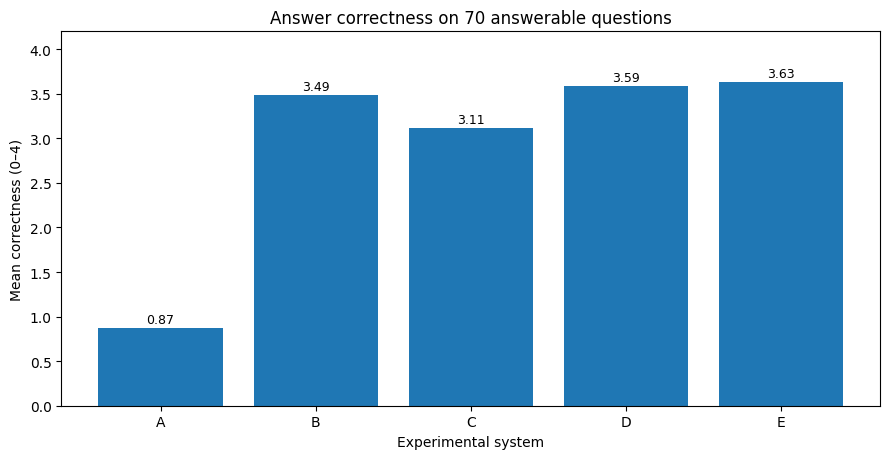

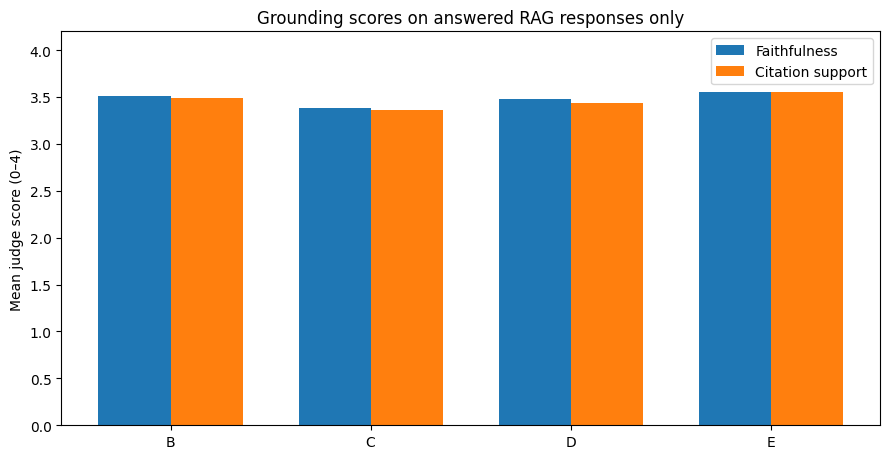

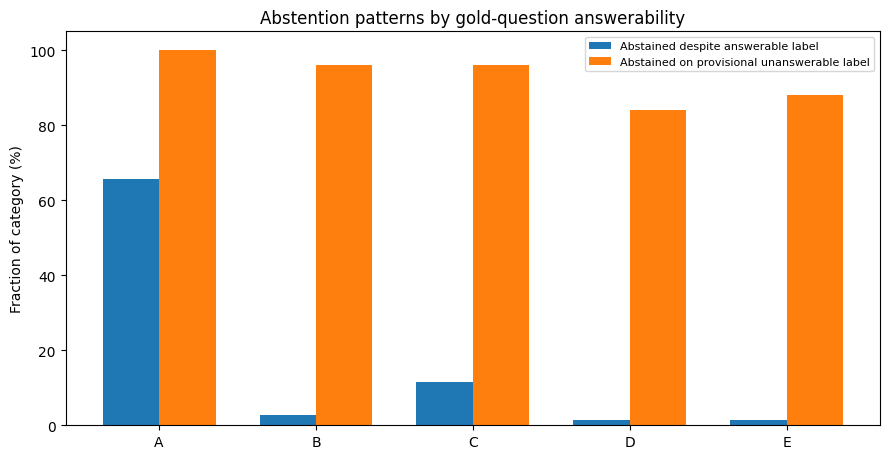

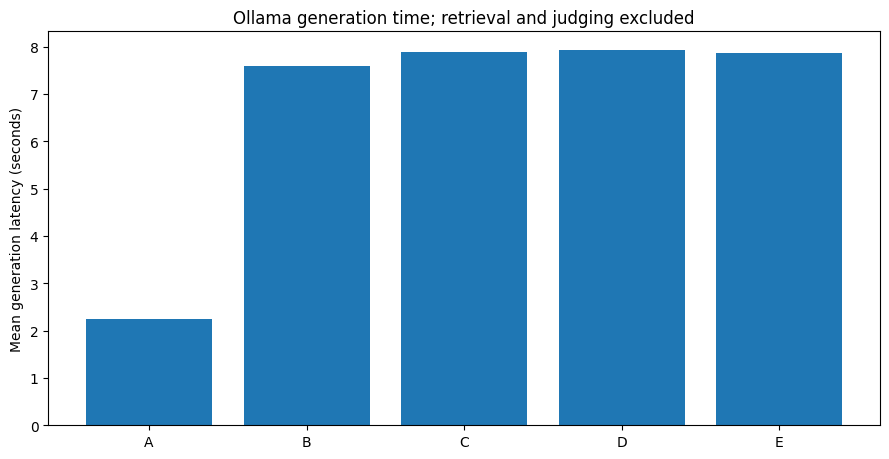

In [6]:
def save_plot(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close()


# Correctness across answerable questions (same 70 questions for each system).
fig, ax = plt.subplots(figsize=(9, 4.7))
x = np.arange(len(system_summary))
bars = ax.bar(x, system_summary.mean_correctness_answerable_0_4)
ax.set_xticks(x, SYSTEM_ORDER)
ax.set_ylim(0, 4.2)
ax.set_ylabel("Mean correctness (0–4)")
ax.set_xlabel("Experimental system")
ax.set_title("Answer correctness on 70 answerable questions")
for i, bar in enumerate(bars):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + .06,
            f"{bar.get_height():.2f}", ha="center", fontsize=9)
save_plot("01_answer_correctness_by_system.png")

# Judge grounding scores, only where applicable.
fig, ax = plt.subplots(figsize=(9, 4.7))
rag_stats = system_summary.loc[system_summary.system.ne("A")]
xs = np.arange(len(rag_stats))
width = .36
ax.bar(xs - width/2, rag_stats.mean_faithfulness_rag_answered_0_4, width, label="Faithfulness")
ax.bar(xs + width/2, rag_stats.mean_citation_support_rag_answered_0_4, width, label="Citation support")
ax.set_xticks(xs, rag_stats.system)
ax.set_ylim(0, 4.2)
ax.set_ylabel("Mean judge score (0–4)")
ax.set_title("Grounding scores on answered RAG responses only")
ax.legend()
save_plot("02_grounding_scores_rag_answered.png")

# Abstention, split by answerability; the latter is provisional.
fig, ax = plt.subplots(figsize=(9, 4.7))
width = .36
ax.bar(x-width/2, system_summary.inappropriate_abstention_rate_answerable * 100,
       width, label="Abstained despite answerable label")
ax.bar(x+width/2, system_summary.provisional_unanswerable_abstention_rate * 100,
       width, label="Abstained on provisional unanswerable label")
ax.set_xticks(x, SYSTEM_ORDER)
ax.set_ylim(0, 105)
ax.set_ylabel("Fraction of category (%)")
ax.set_title("Abstention patterns by gold-question answerability")
ax.legend(fontsize=8)
save_plot("03_abstention_rates.png")

fig, ax = plt.subplots(figsize=(9, 4.7))
ax.bar(x, system_summary.generation_latency_ms_mean / 1000)
ax.set_xticks(x, SYSTEM_ORDER)
ax.set_ylabel("Mean generation latency (seconds)")
ax.set_title("Ollama generation time; retrieval and judging excluded")
save_plot("04_generation_latency_seconds.png")

Breakdown by question category and model disagreement

,system,question_type,n,mean_answer_correctness_0_4,abstention_rate
0,A,direct_factual,22,0.000,1.000
1,B,direct_factual,22,3.955,0.000
2,C,direct_factual,22,3.136,0.136
3,D,direct_factual,22,3.773,0.000
4,E,direct_factual,22,3.773,0.000
5,A,conceptual_explanatory,24,2.042,0.292
6,B,conceptual_explanatory,24,3.625,0.000
7,C,conceptual_explanatory,24,3.500,0.042
8,D,conceptual_explanatory,24,3.750,0.000
9,E,conceptual_explanatory,24,3.833,0.000


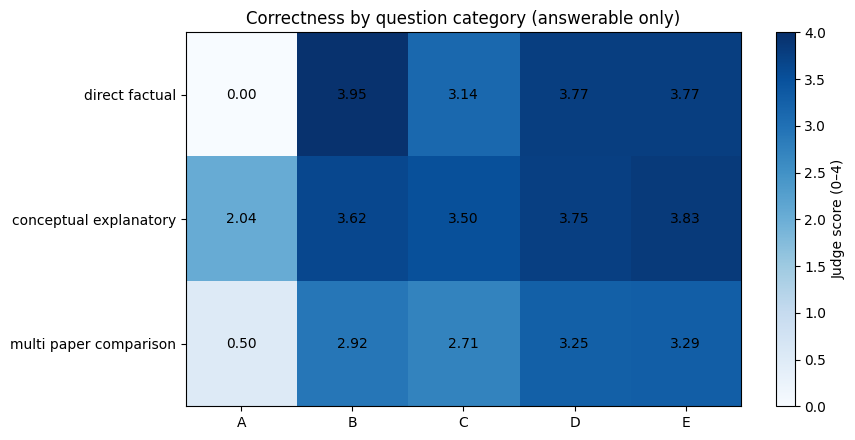

In [7]:
category_rows = []
for (sys, category), sub in results.groupby(["system", "question_type"], sort=False):
    category_rows.append({
        "system": str(sys),
        "question_type": str(category),
        "n": len(sub),
        "answerable_count": int(sub.answerable_bool.sum()),
        "mean_answer_correctness_0_4": numeric_mean(
            sub.loc[sub.answerable_bool], "answer_correctness_0_4"
        ),
        "mean_relevance_0_4": numeric_mean(sub, "answer_relevance_0_4"),
        "mean_faithfulness_answered_0_4": numeric_mean(
            sub.loc[sub.rag_answered], "faithfulness_0_4"
        ),
        "mean_citation_support_answered_0_4": numeric_mean(
            sub.loc[sub.rag_answered], "citation_support_0_4"
        ),
        "abstention_rate": float(sub.abstained.mean()),
        "abstention_alignment": float(sub.abstention_aligned.mean()),
    })
category_summary = pd.DataFrame(category_rows)
category_summary["system"] = pd.Categorical(category_summary["system"], SYSTEM_ORDER, ordered=True)
category_summary["question_type"] = pd.Categorical(
    category_summary["question_type"], QUESTION_ORDER, ordered=True
)
category_summary = category_summary.sort_values(["question_type", "system"])
category_summary.to_csv(OUTPUT_DIR / "metrics_by_question_type.csv", index=False)
display(category_summary[[
    "system", "question_type", "n", "mean_answer_correctness_0_4", "abstention_rate"
]].round(3))

category_heatmap = category_summary.loc[
    category_summary.question_type.ne("unanswerable_insufficient_evidence")
].pivot(index="question_type", columns="system", values="mean_answer_correctness_0_4")
category_heatmap = category_heatmap.reindex(QUESTION_ORDER[:3])[SYSTEM_ORDER]
fig, ax = plt.subplots(figsize=(9, 4.5))
im = ax.imshow(category_heatmap.to_numpy(), cmap="Blues", vmin=0, vmax=4, aspect="auto")
ax.set_xticks(range(5), SYSTEM_ORDER)
ax.set_yticks(range(len(category_heatmap)), [x.replace("_", " ") for x in category_heatmap.index])
for r in range(len(category_heatmap)):
    for c in range(len(SYSTEM_ORDER)):
        ax.text(c, r, f"{category_heatmap.iloc[r, c]:.2f}", ha="center", va="center", fontsize=10)
ax.set_title("Correctness by question category (answerable only)")
fig.colorbar(im, ax=ax, label="Judge score (0–4)")
save_plot("05_correctness_by_question_type_heatmap.png")

# Within-question differences; used later to choose instructive case studies.
answerable_results = results.loc[results.answerable_bool].copy()
correctness_wide = answerable_results.pivot(
    index="question_id", columns="system", values="answer_correctness_0_4"
).reindex(columns=SYSTEM_ORDER)
correctness_wide["max_minus_min"] = correctness_wide[SYSTEM_ORDER].max(axis=1) - correctness_wide[SYSTEM_ORDER].min(axis=1)
correctness_wide["E_minus_D"] = correctness_wide["E"] - correctness_wide["D"]
correctness_wide.reset_index().to_csv(OUTPUT_DIR / "per_question_score_disagreement.csv", index=False)

Paired RAG-system comparisons with uncertainty

In [8]:
BOOTSTRAP_SAMPLES = 4000
rag_pairs = list(combinations(["B", "C", "D", "E"], 2))
rng = np.random.default_rng(SEED)
paired_rows = []
for first, second in rag_pairs:
    aligned = correctness_wide[[first, second]].dropna()
    delta = (aligned[second] - aligned[first]).to_numpy(dtype=float)
    n = len(delta)
    if n != 70:
        raise ValueError(f"Paired analysis needs all 70 answerable questions, got {n}")
    bootstrap_index = rng.integers(0, n, size=(BOOTSTRAP_SAMPLES, n))
    boot_means = delta[bootstrap_index].mean(axis=1)
    wins = int((delta > 0).sum())
    losses = int((delta < 0).sum())
    ties = int((delta == 0).sum())
    p_value = float(binomtest(wins, wins + losses, p=0.5).pvalue) if wins + losses else 1.0
    paired_rows.append({
        "contrast": f"{second} minus {first}",
        "first_system": first,
        "second_system": second,
        "n_answerable_questions": n,
        "mean_difference_second_minus_first": float(delta.mean()),
        "ci95_low": float(np.percentile(boot_means, 2.5)),
        "ci95_high": float(np.percentile(boot_means, 97.5)),
        "second_wins": wins,
        "ties": ties,
        "first_wins": losses,
        "sign_test_p_raw": p_value,
    })

paired_comparisons = pd.DataFrame(paired_rows)
# Holm step-down adjusted p-values; no extra statistics package needed.
raw_p = paired_comparisons.sign_test_p_raw.to_numpy()
order = np.argsort(raw_p)
adj = np.zeros(len(raw_p))
previous = 0.0
for rank, idx in enumerate(order):
    adjusted = min(1.0, (len(raw_p) - rank) * raw_p[idx])
    previous = max(previous, adjusted)
    adj[idx] = previous
paired_comparisons["sign_test_p_holm"] = adj
paired_comparisons["exploratory_holm_p_lt_0_05"] = adj < .05
paired_comparisons.to_csv(OUTPUT_DIR / "paired_rag_comparisons.csv", index=False)
display(paired_comparisons.round(4))

,contrast,first_system,second_system,n_answerable_questions,mean_difference_second_minus_first,ci95_low,ci95_high,second_wins,ties,first_wins,sign_test_p_raw,sign_test_p_holm,exploratory_holm_p_lt_0_05
0,C minus B,B,C,70,-0.3714,-0.7000,-0.0714,8,49,13,0.3833,0.7666,False
1,D minus B,B,D,70,0.1000,-0.0857,0.2714,9,59,2,0.0654,0.1963,False
2,E minus B,B,E,70,0.1429,-0.0714,0.3575,14,52,4,0.0309,0.1235,False
3,D minus C,C,D,70,0.4714,0.1571,0.8000,15,51,4,0.0192,0.0961,False
4,E minus C,C,E,70,0.5143,0.2429,0.8143,15,54,1,0.0005,0.0031,True
5,E minus D,D,E,70,0.0429,-0.1143,0.1857,8,57,5,0.5811,0.7666,False


Citation structure and source mapping audit

In [9]:
def parse_json_list(value):
    if isinstance(value, list):
        return value
    if value is None or (isinstance(value, float) and pd.isna(value)):
        return []
    try:
        data = json.loads(str(value))
    except (TypeError, ValueError):
        return []
    return data if isinstance(data, list) else []


def source_ids_from_metadata(raw):
    return {str(x.get("source_id")) for x in parse_json_list(raw) if isinstance(x, dict) and x.get("source_id")}


citation_records = []
for r in results.itertuples(index=False):
    record = r._asdict()
    inline_ids = set(re.findall(r"\[(S\d+)\]", str(record["answer"])))
    listed_ids = {str(x) for x in parse_json_list(record["citations_json"])}
    context_ids = source_ids_from_metadata(record["all_context_sources_json"])
    cited_meta_ids = source_ids_from_metadata(record["cited_sources_json"])
    rag_answered = bool(record["rag_answered"])
    citation_records.append({
        "question_id": str(record["question_id"]),
        "system": str(record["system"]),
        "rag_answered": rag_answered,
        "inline_id_count": len(inline_ids),
        "listed_id_count": len(listed_ids),
        "context_source_count": len(context_ids),
        "has_inline_marker_if_needed": (len(inline_ids) > 0) if rag_answered else np.nan,
        "inline_matches_listed_if_needed": (inline_ids == listed_ids) if rag_answered else np.nan,
        "all_ids_in_context_if_needed": (
            inline_ids.issubset(context_ids) and listed_ids.issubset(context_ids)
        ) if rag_answered else np.nan,
        "listed_matches_cited_metadata_if_needed": (
            listed_ids == cited_meta_ids
        ) if rag_answered else np.nan,
        "unrecognized_cited_ids": json.dumps(sorted((inline_ids | listed_ids) - context_ids)),
    })

citation_audit = pd.DataFrame(citation_records)
citation_audit.to_csv(OUTPUT_DIR / "citation_structure_audit.csv", index=False)
rag_citations = citation_audit.loc[citation_audit.rag_answered]
print("Answered RAG outputs requiring citations:", len(rag_citations))
for flag in [
    "has_inline_marker_if_needed", "inline_matches_listed_if_needed",
    "all_ids_in_context_if_needed", "listed_matches_cited_metadata_if_needed",
]:
    print(flag, ":", int(rag_citations[flag].eq(True).sum()), "/", len(rag_citations))

Answered RAG outputs requiring citations: 277
has_inline_marker_if_needed : 277 / 277
inline_matches_listed_if_needed : 277 / 277
all_ids_in_context_if_needed : 277 / 277
listed_matches_cited_metadata_if_needed : 277 / 277


Error taxonomy and ranked casebook

In [10]:
citation_lookup = citation_audit.set_index(["question_id", "system"])
error_rows = []
for r in results.itertuples(index=False):
    v = r._asdict()
    flags = []
    if bool(v["answerable_bool"]) and bool(v["abstained"]):
        flags.append("unnecessary_abstention_on_answerable")
    if not bool(v["answerable_bool"]) and bool(v["answered"]):
        flags.append("answered_provisionally_unanswerable")
    if bool(v["answerable_bool"]) and bool(v["answered"]) and float(v["answer_correctness_0_4"]) <= 2:
        flags.append("low_answer_correctness")
    if bool(v["rag_answered"]):
        if float(v["faithfulness_0_4"]) <= 2:
            flags.append("low_faithfulness_judge_score")
        if float(v["citation_support_0_4"]) <= 2:
            flags.append("low_citation_support_judge_score")
        c = citation_lookup.loc[(str(v["question_id"]), str(v["system"]))]
        if not bool(c["has_inline_marker_if_needed"]):
            flags.append("missing_inline_citation")
        if not bool(c["inline_matches_listed_if_needed"]):
            flags.append("inline_json_citation_mismatch")
        if not bool(c["all_ids_in_context_if_needed"]):
            flags.append("citation_id_outside_context")
    error_rows.append({
        "question_id": str(v["question_id"]),
        "system": str(v["system"]),
        "question_type": str(v["question_type"]),
        "answerable": bool(v["answerable_bool"]),
        "status": str(v["status"]),
        "correctness_0_4": v["answer_correctness_0_4"],
        "faithfulness_0_4": v["faithfulness_0_4"],
        "citation_support_0_4": v["citation_support_0_4"],
        "issue_count": len(flags),
        "issue_flags": "; ".join(flags),
    })
error_cases = pd.DataFrame(error_rows)
error_cases = error_cases.sort_values(
    ["issue_count", "question_id", "system"], ascending=[False, True, True]
)
error_cases.to_csv(OUTPUT_DIR / "error_casebook.csv", index=False)
all_flags = Counter(
    flag for string in error_cases.issue_flags for flag in str(string).split("; ") if flag
)
error_counts = pd.DataFrame(
    [{"flag": flag, "n_question_system_pairs": n} for flag, n in all_flags.most_common()]
)
error_counts.to_csv(OUTPUT_DIR / "error_taxonomy_counts.csv", index=False)
print("Flagged issue counts (overlap is possible):")
display(error_counts)
print("Highest-priority records for manual inspection:")
display(error_cases.head(15))

Flagged issue counts (overlap is possible):


,flag,n_question_system_pairs
0,unnecessary_abstention_on_answerable,58
1,low_faithfulness_judge_score,16
2,low_citation_support_judge_score,16
3,low_answer_correctness,10
4,answered_provisionally_unanswerable,9


Highest-priority records for manual inspection:


,question_id,system,question_type,answerable,status,correctness_0_4,faithfulness_0_4,citation_support_0_4,issue_count,issue_flags
27,Q006,C,direct_factual,True,answered,0.0,0.0,0.0,3,low_answer_correctness; low_faithfulness_judge_score; low_citation_support_judge_score
28,Q006,D,direct_factual,True,answered,0.0,0.0,0.0,3,low_answer_correctness; low_faithfulness_judge_score; low_citation_support_judge_score
29,Q006,E,direct_factual,True,answered,0.0,0.0,0.0,3,low_answer_correctness; low_faithfulness_judge_score; low_citation_support_judge_score
72,Q015,C,direct_factual,True,answered,2.0,0.0,0.0,3,low_answer_correctness; low_faithfulness_judge_score; low_citation_support_judge_score
356,Q072,B,unanswerable_insufficient_evidence,False,answered,NaN,0.0,0.0,3,answered_provisionally_unanswerable; low_faithfulness_judge_score; low_citation_support_judge_score
358,Q072,D,unanswerable_insufficient_evidence,False,answered,NaN,0.0,0.0,3,answered_provisionally_unanswerable; low_faithfulness_judge_score; low_citation_support_judge_score
359,Q072,E,unanswerable_insufficient_evidence,False,answered,NaN,0.0,0.0,3,answered_provisionally_unanswerable; low_faithfulness_judge_score; low_citation_support_judge_score
378,Q076,D,unanswerable_insufficient_evidence,False,answered,NaN,0.0,0.0,3,answered_provisionally_unanswerable; low_faithfulness_judge_score; low_citation_support_judge_score
379,Q076,E,unanswerable_insufficient_evidence,False,answered,NaN,0.0,0.0,3,answered_provisionally_unanswerable; low_faithfulness_judge_score; low_citation_support_judge_score
442,Q089,C,unanswerable_insufficient_evidence,False,answered,NaN,0.0,0.0,3,answered_provisionally_unanswerable; low_faithfulness_judge_score; low_citation_support_judge_score


Human audit templates (recommended before final conclusions)

In [11]:
case_flags = error_cases[["question_id", "system", "issue_count", "issue_flags"]]
review_source = results.merge(case_flags, on=["question_id", "system"], validate="one_to_one")


def cited_passage_excerpts(row, max_sources=3, chars_per_source=1200):
    """Present actual saved cited passages for human review, with no inference."""
    sources = parse_json_list(row.get("cited_sources_json", "[]"))
    output = []
    for source in sources[:max_sources]:
        if not isinstance(source, dict):
            continue
        title = str(source.get("title", ""))[:160]
        text = str(source.get("text", ""))[:chars_per_source]
        output.append(f"[{source.get('source_id', '?')}] {title}\n{text}")
    return "\n\n".join(output)


def format_review_template(sample, label):
    fields = [
        "question_id", "system", "question_type", "answerable", "question", "reference_answer",
        "status", "answer", "citations_json", "answer_correctness_0_4",
        "answer_relevance_0_4", "faithfulness_0_4", "citation_support_0_4",
        "judge_reason", "issue_count", "issue_flags",
    ]
    sample = sample.copy()
    sample["cited_passages_for_review"] = sample.apply(cited_passage_excerpts, axis=1)
    # Keep the source metadata readable and the review CSV at a manageable size.
    output = sample[fields + ["cited_passages_for_review"]].copy()
    output.insert(0, "review_sample", label)
    for column in [
        "human_answer_correctness_0_4", "human_faithfulness_0_4",
        "human_citation_support_0_4", "human_abstention_appropriate",
        "human_reference_label_verified", "human_notes", "reviewer_id",
    ]:
        output[column] = ""
    return output


stratified_random = (
    review_source.groupby(["system", "question_type"], group_keys=False)
    .sample(n=2, random_state=SEED)
    .sort_values(["system", "question_type", "question_id"])
)
assert len(stratified_random) == 40
random_review = format_review_template(stratified_random, "stratified_random")
random_review.to_csv(OUTPUT_DIR / "manual_audit_stratified_40.csv", index=False)

targeted = (
    review_source.sort_values(["system", "issue_count", "question_id"],
                              ascending=[True, False, True])
    .groupby("system", group_keys=False)
    .head(6)
)
targeted_review = format_review_template(targeted, "targeted_high_priority")
targeted_review.to_csv(OUTPUT_DIR / "manual_audit_targeted_30.csv", index=False)
print("Random manual review cases:", len(random_review))
print("Targeted manual review cases:", len(targeted_review))
display(random_review[["question_id", "system", "question_type", "issue_flags"]].head(12))

Random manual review cases: 40
Targeted manual review cases: 30


,question_id,system,question_type,issue_flags
150,Q031,A,conceptual_explanatory,unnecessary_abstention_on_answerable
190,Q039,A,conceptual_explanatory,unnecessary_abstention_on_answerable
5,Q002,A,direct_factual,unnecessary_abstention_on_answerable
90,Q019,A,direct_factual,unnecessary_abstention_on_answerable
305,Q062,A,multi_paper_comparison,unnecessary_abstention_on_answerable
340,Q069,A,multi_paper_comparison,
360,Q073,A,unanswerable_insufficient_evidence,
470,Q095,A,unanswerable_insufficient_evidence,
126,Q026,B,conceptual_explanatory,
176,Q036,B,conceptual_explanatory,


Key takeaways and automatically generated report

In [12]:
ranking = system_summary.sort_values("mean_correctness_answerable_0_4", ascending=False)
rag_ranking = system_summary.loc[system_summary.system.ne("A")].sort_values(
    "mean_correctness_answerable_0_4", ascending=False
)
leader = rag_ranking.iloc[0]
baseline = system_summary.loc[system_summary.system.eq("A")].iloc[0]

lines = [
    "# Notebook 11 — Comparative Results and Error Analysis",
    "",
    f"Generated: {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M UTC')}",
    f"Generator: `{run_config.get('ollama_model', 'not recorded')}`; judge: `{judge_config.get('judge_model', 'not recorded')}`",
    f"Notebook 10 generation run ID: `{RUN_ID}`; judge run ID: `{JUDGE_RUN_ID}`",
    "",
    "## Dataset and quality checks",
    "- 95 research questions: 70 answerable and 25 provisionally unanswerable",
    "- Five systems (A–E), 475 distinct question/system pairs",
    "- 475 successful saved generations and 475 evaluated records",
    "- 475/475 judge-to-answer SHA-256 fingerprints matched",
    "",
    "## Main findings (automated judge scores)",
    f"- Highest mean answerable-question correctness among RAG systems: **System {leader['system']}**, "
    f"{leader['mean_correctness_answerable_0_4']:.3f}/4 across 70 answerable questions.",
    f"- No-retrieval System A: {baseline['mean_correctness_answerable_0_4']:.3f}/4 on answerable questions; "
    f"unnecessary abstention rate {baseline['inappropriate_abstention_rate_answerable']:.1%}.",
    "- The system-level results are saved in `system_summary.csv` and `metrics_by_question_type.csv`.",
    "- Paired RAG contrasts and uncertainty intervals are saved in `paired_rag_comparisons.csv`.",
    "",
    "## Core limitations",
    "1. Generation and evaluation both used Qwen3:8B; therefore judge scores are not independently verified.",
    "2. The 25 corpus-insufficiency labels are provisional until manually checked.",
    "3. Citation identifier validity is a structural check, not semantic evidence support.",
    "4. Historical retrieval latency and answer-generation latency were measured at different stages; "
    "do not present their sum as an observed end-to-end benchmark.",
    "5. Sign tests analyze directions of non-tied paired scores; paired bootstrap CIs estimate "
    "differences in mean scores. Human review is necessary before final superiority claims.",
    "",
    "## Recommended next activities",
    "1. Review `manual_audit_stratified_40.csv` and `manual_audit_targeted_30.csv` using the cited passage excerpts.",
    "2. Verify the 25 provisional unanswerable questions against the corpus.",
    "3. Discuss the baseline System A's frequent abstention, and describe it as a prompt-specific finding.",
    "4. Select a deployment system only after balancing correctness, grounding, abstention and latency.",
    "5. Proceed to a user-facing retrieval QA interface and final DAT401 documentation.",
    "",
    "## Figures",
]
for fig_name in sorted(p.name for p in FIG_DIR.glob("*.png")):
    lines.append(f"- `figures/{fig_name}`")
(OUTPUT_DIR / "notebook11_results_brief.md").write_text("\n".join(lines) + "\n", encoding="utf-8")

print("Notebook 11 COMPLETE — no API calls made.")
print("Analysis results saved to:", OUTPUT_DIR)
for file in sorted(OUTPUT_DIR.glob("*")):
    if file.is_file():
        print(" -", file.name)
print("\nSuggested next phase: manual evidence audit, then app integration and documentation.")

Notebook 11 COMPLETE — no API calls made.
Analysis results saved to: /content/drive/MyDrive/NLP Project/data/answer_generation/experimental_study/0e2edaa48dd2/notebook11_analysis
 - authoritative_combined_475.csv
 - citation_structure_audit.csv
 - error_casebook.csv
 - error_taxonomy_counts.csv
 - integrity_report.json
 - manual_audit_stratified_40.csv
 - manual_audit_targeted_30.csv
 - metrics_by_question_type.csv
 - notebook11_results_brief.md
 - paired_rag_comparisons.csv
 - per_question_score_disagreement.csv
 - system_summary.csv

Suggested next phase: manual evidence audit, then app integration and documentation.
